In [ ]:
#Case Study : Student Performance System

In [ ]:
#Create the Classroom dataset
#Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
students = pd.DataFrame({
    "student_id" : ["S101","S102","S103","S104","S105"],
    "course" : ["DA","PFS","DA","PFS","DA"],
    "hours" : [5,8,3,10,6],
    "score" : [55,70,40,85,65],
    "satisfaction" : ["satisfied","Very Satisfied","Neutral","Satisfied","Very Satisfied"]
})
students

,student_id,course,hours,score,satisfaction
0,S101,DA,5,55,satisfied
1,S102,PFS,8,70,Very Satisfied
2,S103,DA,3,40,Neutral
3,S104,PFS,10,85,Satisfied
4,S105,DA,6,65,Very Satisfied


In [ ]:
print("Shape:",students.shape)
print(type(students))
print(students.dtypes)
print(students.size)
print(students.ndim)
print(type(students.values))
print("Missing Values:",students.isna().sum())

Shape: (5, 5)
<class 'pandas.core.frame.DataFrame'>
student_id      object
course          object
hours            int64
score            int64
satisfaction    object
dtype: object
25
2
<class 'numpy.ndarray'>
Missing Values: student_id      0
course          0
hours           0
score           0
satisfaction    0
dtype: int64


In [ ]:
#Count Categories and Summarise Numerical Columns
print("Students per course count:",students['course'].value_counts())
print(students[['hours','score']].describe()) #Descriptive Stats information
#Observe Students Proportion
print((students['course'] == "DA").mean())
print((students['course'] == "PFS").mean())

Students per course count: course
DA     3
PFS    2
Name: count, dtype: int64
           hours      score
count   5.000000   5.000000
mean    6.400000  63.000000
std     2.701851  16.807736
min     3.000000  40.000000
25%     5.000000  55.000000
50%     6.000000  65.000000
75%     8.000000  70.000000
max    10.000000  85.000000
0.6
0.4


In [ ]:
#Python Central tendency and Interpretation
values = np.array([12,15,15,18,20,22,22,22,25,90])
mean_value = np.mean(values)
median_value = np.median(values)
mode_value = pd.Series(values).mode().tolist()
print("Mean:",mean_value)
print("Median",median_value)
print("Mode",mode_value)
print("Sorted Vlaues",np.sort(values))

Mean: 26.1
Median 21.0
Mode [22]
Sorted Vlaues [12 15 15 18 20 22 22 22 25 90]


In [ ]:
#manual Calculation --> Sensitivity in the information -->Spread Outliers and Relationships

In [ ]:
#Day 2 03/11/26

In [ ]:
students.columns

Index(['student_id', 'course', 'hours', 'score', 'satisfaction'], dtype='object')

In [ ]:
#manual Calculation --> Sensitivity in the information -->Spread Outliers and Relationships
#Connect the library result to the manual calculation
values = np.array([12,15,15,18,20,22,22,22,25,90])
total = np.sum(values)
print(total)

261


In [ ]:
count = len(values)
print(count)

10


In [ ]:
manual_mean = total / count
print(f'Manual mean calculation result is {manual_mean}')

Manual mean calculation result is 26.1


In [ ]:
#manual Median calculation
import numpy as np
ordered = np.sort(values)
print(ordered)
middle = count // 2 #10 // 2 --> 5
manual_median = (ordered[middle-1]+ordered[middle])/ 2 #Python indexing starts at 0
print("Manual_Median:",manual_median)

[12 15 15 18 20 22 22 22 25 90]
Manual_Median: 21.0


In [ ]:
#Demonstrate the sensitivity to an extreme value
print(values)
#Exclude 90 only for a comparison,retaining the original array
comparision_values = values[values!=90]
comparision_values
print("Original Mean",np.mean(values))
print("Mean Excludion 90:",np.mean(comparision_values))
#Expected 26.1 and 19.0 --> The Boolean mask selects values that differ from 90,

[12 15 15 18 20 22 22 22 25 90]
Original Mean 26.1
Mean Excludion 90: 19.0


In [ ]:
#Python spread outliers and relationships
scores_a = np.array([58,60,62])
scores_b = np.array([20,60,100])
for name,scores in [("Akash",scores_a),("Sanjay",scores_b)]:
  print(name,scores)
  print(name,"Mean = ",np.mean(scores),
        "Range:",np.max(scores)-np.min(scores),
        "Population Std",round(np.std(scores),2))
  #Standard Deviation --> It quantifies the amount of variation or spread in a set of
  #data points relative to its mean
  #Low Standard Deviation --> Indicates that the datapoints tend to be very close to mean
  #High Standard Deviation --> Indicates that the data pooints are spread over a wider range

Akash [58 60 62]
Akash Mean =  60.0 Range: 4 Population Std 1.63
Sanjay [ 20  60 100]
Sanjay Mean =  60.0 Range: 80 Population Std 32.66


In [ ]:
#Flag unusual values using the IQR (Inter Quartile Range)
print(values)
q1,q3 = np.percentile(values,[25,75])
print(q1)
print(q3)
iqr = q3 - q1 #Q1 -> Lower quartile,Q3 --> Upper Quartile
print(iqr)
lower = q1 - (1.5)*iqr
upper = q3 + (1.5)*iqr
print(lower)
print(upper)
flagged = values[(values < lower) | (values > upper)]
print("Q1:",q1,"Q3:",q3,"IQR:",iqr)
print("Fences:",lower,upper)
print("Flagged Value(s) [Outliers]:",flagged)

[12 15 15 18 20 22 22 22 25 90]
15.75
22.0
6.25
6.375
31.375
Q1: 15.75 Q3: 22.0 IQR: 6.25
Fences: 6.375 31.375
Flagged Value(s) [Outliers]: [90]


Pearson Correlation: 0.985


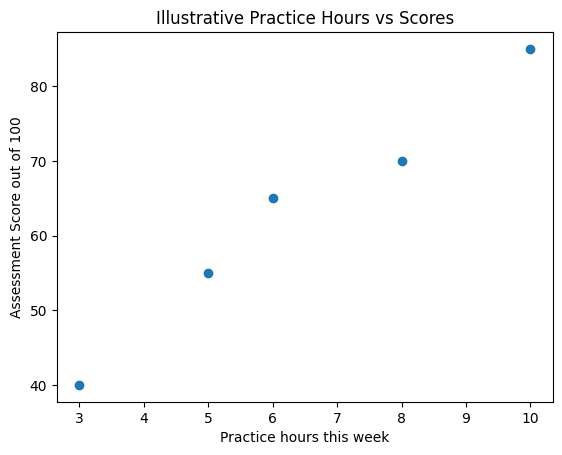

In [ ]:
#Exploring Numerical Relationship
import matplotlib.pyplot as plt
result = students["hours"].corr(students['score']) #Pearson Correlation
#Pearson Correlation (r) -->It is a statistical measure that quantifies the
#strength and direction of a linear relationship between two continuous variables
#+1.0 --> Perfectly positive -->As variable x increases,y also increases in aperfect
#st.line
#-1.0 -->Perfectly negative --> As variable x increases,variable y decreases
#0.0 (No linear correlation) --> there is no linear relation b/w variables
result
print("Pearson Correlation:",round(result,3))
plt.scatter(students["hours"],students['score'])
plt.xlabel("Practice hours this week")
plt.ylabel("Assessment Score out of 100")
plt.title("Illustrative Practice Hours vs Scores")
plt.show()

In [ ]:
#Datatypes,Central Tendency and a First look at spread
#Variance,Standard Deviation,Quartiles and the IQR rule

#Range --> First measure of spread  --> Range = Maximum - Minimum
#Student A --> Scores --> 58,60,62 --> Mean --> 60 --> Deviations --> 58-60 = -2, 60-60 = 0, 62-60 = 2
#Student B --> Scores --> 20,60,200 --> Mean -->60 --> Deviations -->-40,0,40
#For both students,the deviations add to zero.Averaged signed deviations would hide the
#spread.Squaring makes the contributions non negative and gives greater weight to larger
#deviations
#Scores -> A --. deviation as follows
'''
Score x           Mean.             Deviation (x-mean)                  Squared Deviations
58                 60                     -2                                   4
60                 60                      0                                   0
62                 60                      2                                   4

Total Sqd deviation = 4 + 0 + 4 = 8 --> Population variance = 8 / 3 = 2.667 marks squared
Population Variance = Sum of Squared deviations / N
Population Standard deviation = Square root[Summation (xi - u)**2] / N #xi --> each individual value
u --> population mean
Population Std Deviation --> sqrt(2.667) --> 1.663 marks
'''
print(scores_a)
print(scores_b)
mean_a = np.mean(scores_a)
print(mean_a)
deviations = scores_a - mean_a
print(deviations)
squared_deviations = deviations**2
squared_total = np.sum(squared_deviations)
print(squared_total)
variance_a = squared_total / len(scores_a)
print(variance_a)
std_a = np.sqrt(variance_a)
print(std_a)

[58 60 62]
[ 20  60 100]
60.0
[-2.  0.  2.]
8.0
2.6666666666666665
1.632993161855452


In [ ]:
#Day 3 04/11/26

In [ ]:
#Comparing both scores and both denominators
for name,scores in [("A",scores_a),('B',scores_b)]:
  print(name,"range",np.ptp(scores),
        "PoP Std",np.std(scores),
        "Sample Std",np.std(scores,ddof=1))

A range 4 PoP Std 1.632993161855452 Sample Std 2.0
B range 80 PoP Std 32.65986323710904 Sample Std 40.0


In [ ]:
#Quartiles IQR and Outlier Screening
#values
q1,median,q3 = np.percentile(values,
                             [25,50,75],
                             method="linear")
print(q1)
print(q3)
print(median)
iqr = q3 - q1
print(iqr)
lower_fence = q1 - 1.5*iqr
upper_fence = q3 + 1.5*iqr
outlier_mask = (values < lower_fence) | (values > upper_fence)
print("Flagged Values:",values[outlier_mask].tolist())

15.75
22.0
21.0
6.25
Flagged Values: [90]


In [ ]:
#Preserve the observations with review labels
review = pd.DataFrame({
    "Observations_Id" : np.arange(1,len(values)+1),
    "Value":values,
    "IQR_Flag":outlier_mask
})
review

,Observations_Id,Value,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
d = review.to_string(index=False)
print(d)
print(type(d))

 Observations_Id  Value  IQR_Flag
               1     12     False
               2     15     False
               3     15     False
               4     18     False
               5     20     False
               6     22     False
               7     22     False
               8     22     False
               9     25     False
              10     90      True
<class 'str'>


In [ ]:
print("Flagged IDs",review.loc[review["IQR_Flag"],
                               "Observations_Id"].tolist())

Flagged IDs [10]


In [ ]:
print(lower_fence)
print(upper_fence)
print(q1,median,q3)

6.375
31.375
15.75 21.0 22.0


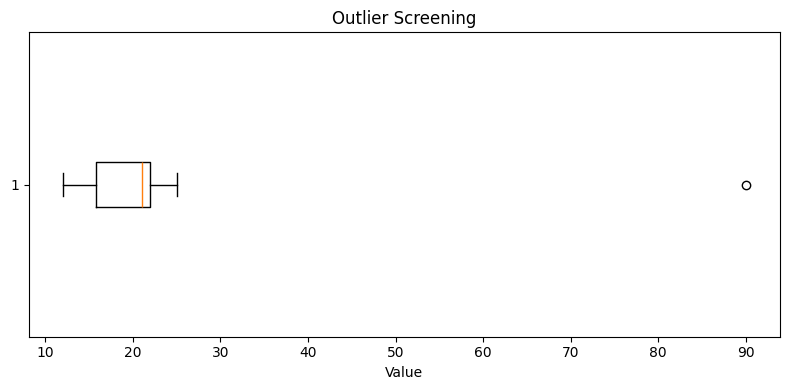

In [ ]:
#Python Box and Whisker Plot
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize= (8,4))
ax.boxplot(values,vert=False,whis=2.5)
ax.set_xlabel("Value")
ax.set_title("Outlier Screening")
fig.tight_layout()
plt.show()
#Expecting a boz from 15.75 to 22 a median at 21,whiskers at 21,and separate marker at 90 which indicates
#outlier,with whiskers pointing at 6.375 and upper_fence at 31.375

In [ ]:
#Explain Sensitivity without deleteing data
comparision = values[~outlier_mask]
print(comparision)
print("All Mean",np.mean(values))
print("Comparision Mean",np.mean(comparision))
print("All Median",np.median(values))
print("Comparision Median",np.median(comparision))
#Comparision is only used to demostrate the sensitivity;values and review still preserve
#the original records

[12 15 15 18 20 22 22 22 25]
All Mean 26.1
Comparision Mean 19.0
All Median 21.0
Comparision Median 20.0


Signed Deviations cancel and Squared
Deviations reveal spread
Variance uses Squared units,STD used
Original units
IQR fences and Box and whisker plot
endpoint are important
Outlier detection creates a review flag,not
a deletion instruction

In [ ]:
#Positive and Negative Covariance using Paired deviations
#Pearson Correlation from Covariance and Std devations
#Linear Association from Monotonic Association and Casuation
#Python to verify the calculations and inspect scatter plots
students

,student_id,course,hours,score,satisfaction
0,S101,DA,5,55,satisfied
1,S102,PFS,8,70,Very Satisfied
2,S103,DA,3,40,Neutral
3,S104,PFS,10,85,Satisfied
4,S105,DA,6,65,Very Satisfied


In [ ]:
#create a new observation table
data = pd.DataFrame({
    'Observation':np.arange(1,7),
    'Practice_Hours':[2,4,5,7,8,10],
    'Assessment Score':[35,48,55,68,74,90]
})
data

,Observation,Practice_Hours,Assessment Score
0,1,2,35
1,2,4,48
2,3,5,55
3,4,7,68
4,5,8,74
5,6,10,90


In [ ]:
#Variance --> multiplies a variable deviation by itself.
#CoVariance --> multiplies the deviation in X by the paired deviation in Y.
'''
X deviation                     Y deviation                   Product                Contribution
Positive.                        Positive                      Positive.                Both above their means
Negative                         Negative.                     Positive                 Both below their means
Positive.                        Negative                      Negative                 Opposite sides of their means
Negative                         Positive.                    Negative.                 Opposite sides of their means

Population Copvariance = Sum of (xi - population mean of X) * (yi - population mean of Y)
                         ----------------------------------------------------------------
                                                        N
Sample Covariance = Sum of (xi - sample mean of X) * (yi-sample mean of Y) / n-1

xi and yi are paired values,N is population size,n is the sample size
'''
data[['Practice_Hours','Assessment Score']]
#x - mean x (Hours --> x) (mean_x --> x)
#x1 --> x1 - meanx --> 2 - 6 --> -4
#x2 --> 4-6 --> -2
#x3 --> 5-6 --> -1
#x4 --> 1
#x5 --> 2
#x6 --> 4
#y- mean_y --> (Scores -->y) --> mean_y --> 61.67
#y1 --> 35-61.67 --> -26.67
#y2 --> -13.67
#y3 --> -6.67
#y4 --> 6.33
#y5 --> 12.333
#y6 --> 28.33
#product --> x1*y1 -> 106.67
#x2*y2 -->27.33
#x3*y3 -->6.67
#x4*y4 -->6.33
#x5*y5 -->24.67
#x6*y6 -->113.33
#sum of deviation products = 285. --> Population cov = 285 / 6 -->47.5
#sample covariance = 285 / 5 -> 57
#Both are positive,indication is more hours --> higher score

,Practice_Hours,Assessment Score
0,2,35
1,4,48
2,5,55
3,7,68
4,8,74
5,10,90


In [ ]:
#Day 4 05/11/26

In [ ]:
#PYTHON Covariance
hours = np.array([2,4,5,7,8,10],dtype=float)
#hours
scores = np.array([35,48,55,68,74,90],dtype=float)
data = pd.DataFrame({"Hours":hours,'Scores':scores})
#data
print("Shape is:",data.shape)
print("Missing Values:",data.isna().sum().to_dict())
#cal covariance from deviations
#we will create the variables as per formula
n = len(hours)
dx = hours - np.mean(hours)
print(dx)
dy = scores -np.mean(scores)
print(dy)
products = dx*dy
print(products)
cross_total = np.sum(products)
pop_cov = cross_total/n
sample_cov = cross_total/ (n-1)
print("Product Total",cross_total)
print("Population Covariance",pop_cov)
print("Sample Covariance",sample_cov)

Shape is: (6, 2)
Missing Values: {'Hours': 0, 'Scores': 0}
[-4. -2. -1.  1.  2.  4.]
[-26.66666667 -13.66666667  -6.66666667   6.33333333  12.33333333
  28.33333333]
[106.66666667  27.33333333   6.66666667   6.33333333  24.66666667
 113.33333333]
Product Total 285.0
Population Covariance 47.5
Sample Covariance 57.0


why standardise covariance--->A Covariance changes in above case if hours are expressed in minutes...

Correlation divides the covariance by Standard Deviations of both variables so that the units cancel and mainly values lies b/w-1 and +1,provided both variables have nonzero variation
Sample Pearson Correlation =
(r) = Sampke Covariance (X,Y) / (Sample Std Deviation of X * Sample Deviation of Y)..

for above observations,sample variance of hours --> Summation (xi - mean_x)**2 / n-1
--> (2-6)**2 + (4-6)**2 + (5-6)**2 + (7-6) **2 + (8-6)**2 + (10-6)**2 / 5
-->16 + 4 + 1 + 1 + 4 + 16 / 5 -> 8.4

Sample Std Deviation --> Sqrt(Sample Variance). --> 2.89

Sample variance of scores -> 387.466
Sample Std Deviation --> 19.6

Sample Pearson Correlation(r) = 57 /(2.89*19.6) --> ~1 This describes a very strong positive linear association in given 6 observations...

Covariance compared with correlation
Property.                   Covariance.                     Perason
Correlation
-->Units                   Product of two units.               
unitless
-->Range.                  No fixed bounds.                    -1 to
+1defined
-->Positive unit rescaling changes magnitude
unchanged
Purpose.                   Describes Joint variation.
Describe linear association (direction and
strength)

#A negative rescaling reverses the
correlation sign.Adding a constant to either
variable leaves Pearson Correlation unchange.

In [ ]:
#Verify and Standardise
cov_matrix = np.cov(hours,scores,ddof=1)
print(cov_matrix)
r_manual = sample_cov / (np.std(hours,ddof=1)*(np.std(scores,ddof=1)))
r = np.corrcoef(hours,scores)[0,1]
print(f'Manual r is {round(r_manual,4)}')
print(f'Using Numpy value of r is {round(r,4)}')

[[  8.4         57.        ]
 [ 57.         387.46666667]]
Manual r is 0.9991
Using Numpy value of r is 0.9991


In [ ]:
#Ranks and Careful Analytical conclusions
#Pearson and Spearman
#Pearson measures linear association between numerical variables
#Spearman is Pearson Correlation of the ranks and meaures monotonic association;whether the values are
#consistently tend to increase together or move in opoosite...
#Montonic --> It is a trend where two variables movie in a concise relative direction,but
#necessarily at a constant rate...
#Linear -->Perfect St.line
#Monotonic -->can be straight line or a curve that never reverses direction

#For x = [1,2,3,4,5], y = [1,4,9,16,25] both rank lists --> [1,2,3,4,5],
#Spearman Correlation --> 1
#Pearson Correlation --> 0.99
#pandas --> rank() assigns average ranks by default

In [ ]:
#Python unit changes ranks and edge cases
minutes = hours * 60
print(minutes)
cov_minutes = np.cov(minutes,scores)[0,1]
print(cov_minutes)
r_minutes = np.corrcoef(minutes,scores)
print(r_minutes)
print("Pandas Correlation:",data.corr())
#we have received Expected Covariance as 3420 minutes * marks --> Correlation is making
#same value around 0.9991

#Cal Spearman through ranks
x_rank_demo = pd.Series([1,2,3,4,5])
y_rank_demo = pd.Series([1,4,9,16,25])
pearson_demo = x_rank_demo.corr(y_rank_demo)
print(pearson_demo)
x_ranks = x_rank_demo.rank()
print("X ranks",x_ranks)
y_ranks = y_rank_demo.rank()
print("Y ranks",y_ranks)
print("Spearman:",round(x_ranks.corr(y_ranks),4))

[120. 240. 300. 420. 480. 600.]
3420.0
[[1.         0.99912089]
 [0.99912089 1.        ]]
Pandas Correlation:            Hours    Scores
Hours   1.000000  0.999121
Scores  0.999121  1.000000
0.981104910251593
X ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Y ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Spearman: 1.0


In [ ]:
#Python Scatter plots and nonlinear plots

In [ ]:
#Compare a line-like pattern with curve

[-2. -1.  0.  1.  2.]
[4. 1. 0. 1. 4.]
0.0


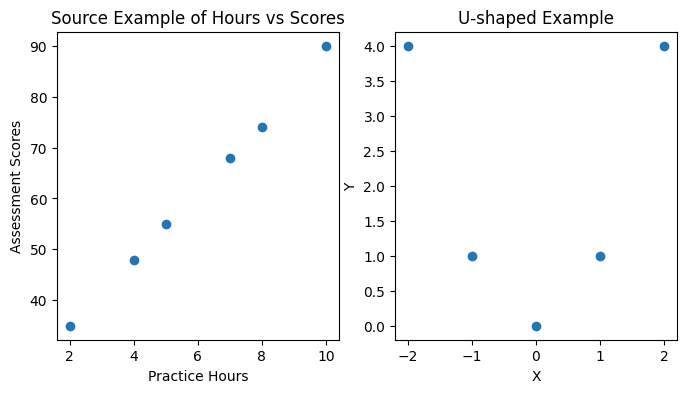

In [ ]:
curve_x = np.array([-2,-1,0,1,2],dtype=float)
curve_y = curve_x**2
print(curve_x)
print(curve_y)
curve_r = np.corrcoef(curve_x,curve_y)[0,1]
print(curve_r)
#display the plot for above mentioned data
fig,axes = plt.subplots(1,2,figsize=(8,4))
axes[0].scatter(hours,scores)
axes[0].set(xlabel="Practice Hours",
            ylabel ="Assessment Scores",title="Source Example of Hours vs Scores")
axes[1].scatter(curve_x,curve_y)
axes[1].set(xlabel="X",ylabel="Y",title="U-shaped Example")
plt.show()

In [ ]:
#Day 5 06/11/26

In [ ]:
#Task 1: For x =[1,2,3] and y=[2,4,6], for both covariance formulas and Pearson r.

In [ ]:
x = np.array([1,2,3],dtype=float)
y = np.array([2,4,6],dtype=float)
data = pd.DataFrame({"X":x,"Y":y})
#data
print("Shape is:",data.shape)
print("Missing Values:",data.isna().sum().to_dict())
#cal covariance from deviations
#we will create the variables as per formula
n = len(x)
dx = x - np.mean(x)
print(dx)
dy = y -np.mean(y)
print(dy)
products = dx*dy
print(products)
cross_total = np.sum(products)
pop_cov = cross_total/n
sample_cov = cross_total/ (n-1)
print("Product Total",cross_total)
print("Population Covariance",pop_cov)
print("Sample Covariance",sample_cov)

Shape is: (3, 2)
Missing Values: {'X': 0, 'Y': 0}
[-1.  0.  1.]
[-2.  0.  2.]
[2. 0. 2.]
Product Total 4.0
Population Covariance 1.3333333333333333
Sample Covariance 2.0


In [ ]:
cov_matrix = np.cov(x,y,ddof=1)
print(cov_matrix)
r_manual = sample_cov / (np.std(hours,ddof=1)*(np.std(scores,ddof=1)))
r = np.corrcoef(x,y)[0,1]
print(f'Manual r is {round(r_manual,6)}')
print(f'Using Numpy value of r is {round(r,4)}')

[[1. 2.]
 [2. 4.]]
Manual r is 0.035057
Using Numpy value of r is 1.0


Probability Distributions -->

It describes the possible values of a random variable and how does probability
is assigned to them..
It connects uncertainity to the mean, variance and standard deviation which we have discussed.

Random Experiment --> It has an outcome that is not known with certainity in advance.A random variable will assign a numerical value to each outcome...we use X for variable..

x or k denotes for possible result

For one Assessment let X = 1 (Pass),X=0
otherwise --> Let Y be number os passess..
Let T be time completion in minutes..

Discrete        ---> A finites or countability
infinite set          0,1,2,3,,,,,,,,,, calls
in a minute

Continuous      --> Any value in a continuous
interval.      --> task diration in minutes

Observed Frequency describe a dataset.

Probability model will describe a proposed
mechanism that generates observations...

Eg: 6 passes out of 10 attempts -->
Proportion -->6 / 10 --> 0.6
A small dataset will not establish exact
probability for every future dataset.

PMP ,PDF , CDF -->
PMF --> Probability Mass Function
--> it gives the exact probability that a discret random variable equalts to a pecific value

p(x) = P(X=x)

-->Every probability outcome must be between 0 and 1
--> The sum of all probabilities across all possible values equal to 1

--> Rolling a 3 on fair six sided diw
p(X=3) = 1 / 6

PDF --> Probability DEnsity Function

--> It describes the probability density (likelihood per unit length) of a continuous random variabkle..(measures like height,weight,time...)
 --> Probability of a cont.variable taking one exact single point alaways P(X=x) = 0
 -->It is calculated by area under the curve..
 --> Person's height falling between 160cms to 180cms by integrating PDF over that range..


CDF --> Cumulative Density Function
-->It describes the cumulative probability that a random variable is less than or equal to given value (x) --> F(x) = P(X<=x)

-->Can be applied for both discrete and continuous CDF values 0 and 1
-->Discrete variables --> It forms a step function
-->Continuous variables -->It is a smooth,S shaped curve

P(X=4) = 1 / 6 and P(X<=4) = 4 / 6

In [ ]:
import numpy as np
#!pip install scipy
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:
#Bernoulli Distribution --> It model one trial with two possible outcomes
#1 for Success,0 for Failue
#P(X=x) = p^x(1-p)^1-x, x E {0,1}
#p -->Probability of X=1; 0<=p<=1
#Support --> 0 and 1
#Mean -->p;Variance --> p(1-p);Std --> Sqrt(p(1-p))

p = 0.6 #model assigns probability to pass one assessment
pass_prob = stats.bernoulli.pmf(1,p)
fail_prob = stats.bernoulli.pmf(0,p)
bernoulli_mean = p
bernoulli_var = p*(1-p)
print(f'PAss:',round(pass_prob,4))
print(f'Fail:',round(fail_prob,4))
print(f'Mean:',bernoulli_mean)
print("Variance:",bernoulli_var)
print("Standard Deviation:",round(np.sqrt(bernoulli_var),4))
#p sets the success probability,pass_prob and fail_prob --> exact probabilities
#bernoulli_var describes the theoritical variance..

PAss: 0.6
Fail: 0.4
Mean: 0.6
Variance: 0.24
Standard Deviation: 0.4899


In [ ]:
#Day 6 07/11/26

Binomial Distribution::
Connection to binary data --> Yes/no -->
Bernoulli

Counting how may yes outcomes across a
fixed set of independent trials with the same
probability leads to Binomial distribution.

A Binomial variable counts successes in a
fixed number n of independent Bernoulli
trials with the same success probability p..

P(X=k) = (nk)p^k(1-p)n-k
Binomial Coeeficient C(n,k) = n!/([k!(n-k)!])
counts the arrangements of k successes among
n trials..
Mean =np,Variance = np(1-p),Std = sqrt(np(1-p))


In [ ]:
#Assume five independent assessments,each with probability 0.6.Let X be the total passes.
#For exactly three passes; n = 5,k=3,p =0.6
#There are C(5,3) = 5! / 3!*2! --> 10
#One part.sequence with three passes and two failures has probability
#0.6 ** 3 * 0.4 **2 --> 0.03456..Therefore p(X=3) = 10*0.03456 --> 0.3456
#Mean = 5*0.6 -> 3 passes
#Variance = np(1-p) -> 3 *(1-0.6) -> 3 * 0.4 --> 1.2
#Std --> 1.09

In [ ]:
#let us link above scenario to our Python example with exact and cumulative probabilities
n,p = 5,0.6 #n --> fixed trail count,
#p is the probability per trail pmf(3) only three passes.cdf(3) --> probabilities
#for 0 through 3,sf(2) --> adds probabilities for 3 through 5
exact_three = stats.binom.pmf(3,n,p)
print(f'PMF p(X=3) --> {exact_three}')
at_most_three = stats.binom.cdf(3,n,p)
print(f'Atmost Three--> {round(at_most_three,4)}')
at_least_three = stats.binom.sf(2,n,p)
print(f'Atleast Three --> {round(at_least_three,5)}')

PMF p(X=3) --> 0.3455999999999997
Atmost Three--> 0.663
Atleast Three --> 0.68256


The result is conditional on the model
assumptions.Repeated Assessments of the same
person may have dependence or different
difficulty..In that case,a common
independent trial binomial model is suitable

Poisson Distribution --> A Poisson Variable
models he number of events in a fixed time,
area,distance or a volume.

It processes the events which occur with
independent increments and a constant rate..
The count has no fixed upper limit

P(X=k) = (Lambda^k)(exponential - lambda) /
k! , k = 0,1,2.......

Lambda --> expected number of events in the
specified interval.it must be non negative..
Mean = Lambda,Variance = Lambda...
If the rate is r events per time unit over t
units
lambda = r * t

Assume a Support Desk receives calls
according to Poisson process with rate 3
calls per minute..
Over one minute = lambda = 3

For exactly 2 calls p(X=2) e^-3*3^2 / 2!
--> 0.2240

For atleast one call,use the complement
p(X>=1) = 1 1 - p(X=0) = 1 - e-^3(1) -> 0.95

#Over two minutes the expected count becomes 6 not 3

In [ ]:
lam = 3 #from above scenario
exact_two = stats.poisson.pmf(2,lam)
print(f"Exact two: {exact_two}")
atleast_one = stats.poisson.sf(0,lam)
print(f"atleast one: {atleast_one}")
atleast_five = stats.poisson.sf(4,mu=lam)
print("atleast Five: {atleast_five}")
print("two Minute mean:",lam*2)
print("Mean:",lam,"variance",lam)
#variable roles -->lam stores the expected count per one minute interval..
#Scipy use parameter mu --> lam ->Atleast five cases which includes -->5,6,7 and above...

Exact two: 0.22404180765538775
atleast one: 0.950212931632136
atleast Five: {atleast_five}
two Minute mean: 6
Mean: 3 variance 3
